# Mini PACS AI - Integração Orthanc → API de Inferência

Este notebook demonstra o fluxo completo:
1. Lista todas as instâncias DICOM armazenadas no Orthanc
2. Baixa cada instância via API REST do Orthanc
3. Envia para a API de inferência (`/predict`)
4. Exibe a imagem e as probabilidades de achados radiológicos

## 1. Imports e Configuração

In [1]:
import requests
import pydicom
import matplotlib.pyplot as plt
import io
from typing import List, Dict
import pandas as pd

# URLs dos serviços (nomes internos do Docker)
ORTHANC_URL = "http://orthanc:8042"
INFERENCE_API_URL = "http://inference-api:8000"

print("✓ Imports realizados com sucesso")
print(f"✓ Orthanc: {ORTHANC_URL}")
print(f"✓ API: {INFERENCE_API_URL}")

✓ Imports realizados com sucesso
✓ Orthanc: http://orthanc:8042
✓ API: http://inference-api:8000


## 2. Funções Auxiliares

In [2]:
def list_instances() -> List[str]:
    """
    Lista todos os IDs de instâncias DICOM armazenadas no Orthanc.
    """
    response = requests.get(f"{ORTHANC_URL}/instances")
    response.raise_for_status()
    return response.json()


def download_dicom(instance_id: str) -> bytes:
    """
    Baixa o arquivo DICOM bruto de uma instância específica.
    """
    response = requests.get(f"{ORTHANC_URL}/instances/{instance_id}/file")
    response.raise_for_status()
    return response.content


def get_instance_info(instance_id: str) -> Dict:
    """
    Obtém informações sobre uma instância DICOM.
    """
    response = requests.get(f"{ORTHANC_URL}/instances/{instance_id}/simplified-tags")
    response.raise_for_status()
    return response.json()


def call_inference_api(dicom_bytes: bytes) -> Dict:
    """
    Envia arquivo DICOM para a API de inferência e retorna as probabilidades.
    """
    files = {"dicom_file": ("image.dcm", dicom_bytes, "application/dicom")}
    response = requests.post(f"{INFERENCE_API_URL}/predict", files=files)
    response.raise_for_status()
    return response.json()


def display_image_and_predictions(dicom_bytes: bytes, predictions: Dict, title: str = ""):
    """
    Exibe a imagem DICOM e as top 5 probabilidades.
    """
    # Lê a imagem DICOM
    dcm = pydicom.dcmread(io.BytesIO(dicom_bytes))
    pixel_array = dcm.pixel_array

    # Cria figura com 2 subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

    # Plot da imagem
    ax1.imshow(pixel_array, cmap="gray")
    ax1.set_title(title if title else "Imagem DICOM")
    ax1.axis("off")

    # Plot das probabilidades (top 5)
    probs = predictions.get("probabilities", {})
    top_5 = dict(list(probs.items())[:5])

    labels = list(top_5.keys())
    values = list(top_5.values())

    ax2.barh(labels, values, color="steelblue")
    ax2.set_xlabel("Probabilidade")
    ax2.set_title("Top 5 Achados Radiológicos")
    ax2.set_xlim(0, 1)

    # Adiciona valores nas barras
    for i, v in enumerate(values):
        ax2.text(v + 0.01, i, f"{v:.3f}", va="center")

    plt.tight_layout()
    plt.show()

    # Mostra metadados se disponíveis
    if "metadata" in predictions and predictions["metadata"]:
        print("\nMetadados DICOM:")
        for key, value in predictions["metadata"].items():
            print(f"  {key}: {value}")

print("✓ Funções auxiliares definidas")

✓ Funções auxiliares definidas


## 3. Verificar Status dos Serviços

In [3]:
# Verifica Orthanc
try:
    response = requests.get(f"{ORTHANC_URL}/system")
    response.raise_for_status()
    print("✓ Orthanc está respondendo")
    print(f"  Versão: {response.json().get('Version', 'N/A')}")
except Exception as e:
    print(f"✗ Erro ao conectar com Orthanc: {e}")

# Verifica API de Inferência
try:
    response = requests.get(f"{INFERENCE_API_URL}/health")
    response.raise_for_status()
    data = response.json()
    print("✓ API de Inferência está respondendo")
    print(f"  Status: {data.get('status', 'N/A')}")
    print(f"  Modelo carregado: {data.get('model_loaded', False)}")
except Exception as e:
    print(f"✗ Erro ao conectar com API de Inferência: {e}")

✓ Orthanc está respondendo
  Versão: 1.12.9
✓ API de Inferência está respondendo
  Status: healthy
  Modelo carregado: True


## 4. Listar Instâncias Disponíveis no Orthanc

In [4]:
instances = list_instances()
print(f"Total de instâncias DICOM no Orthanc: {len(instances)}")

if instances:
    print("\nIDs das instâncias:")
    for i, instance_id in enumerate(instances, 1):
        print(f"  {i}. {instance_id}")
else:
    print("\n⚠️  Nenhuma instância encontrada no Orthanc.")
    print("   Por favor, faça upload de arquivos DICOM via interface web:")
    print(f"   {ORTHANC_URL}")

Total de instâncias DICOM no Orthanc: 9

IDs das instâncias:
  1. 1a368e54-0a0a28a0-c5be7bc2-8a4c7492-aa9d3468
  2. 1f2d2901-0e995924-103fdbf4-8aacb8be-4279c8da
  3. 25cc82b9-38583a9e-8a08fc15-f4892024-28b8584b
  4. 70d0117e-60d4002b-cbbe9042-3b57555a-e88bfd99
  5. 76a9a673-cdfbc0e8-efa364cc-27c25423-aad7ec6c
  6. 8206ee5f-8f834b42-042e6a40-705b72da-bc7ce3a3
  7. 89713983-98986f53-c67e566f-6786c944-1697687d
  8. b8eaee70-ed5ace3a-2f77895e-8105e3d3-ec3508ce
  9. f816ed6a-8177f2bc-53267934-dc56e141-86749fb2


## 5. Processar Todas as Instâncias

Processando 9 instância(s)...

Instância 1/9 - ID: 1a368e54-0a0a28a0-c5be7bc2-8a4c7492-aa9d3468
  → Baixando arquivo DICOM...
    Tamanho: 14446620 bytes
  → Chamando API de inferência...
    Inferência concluída


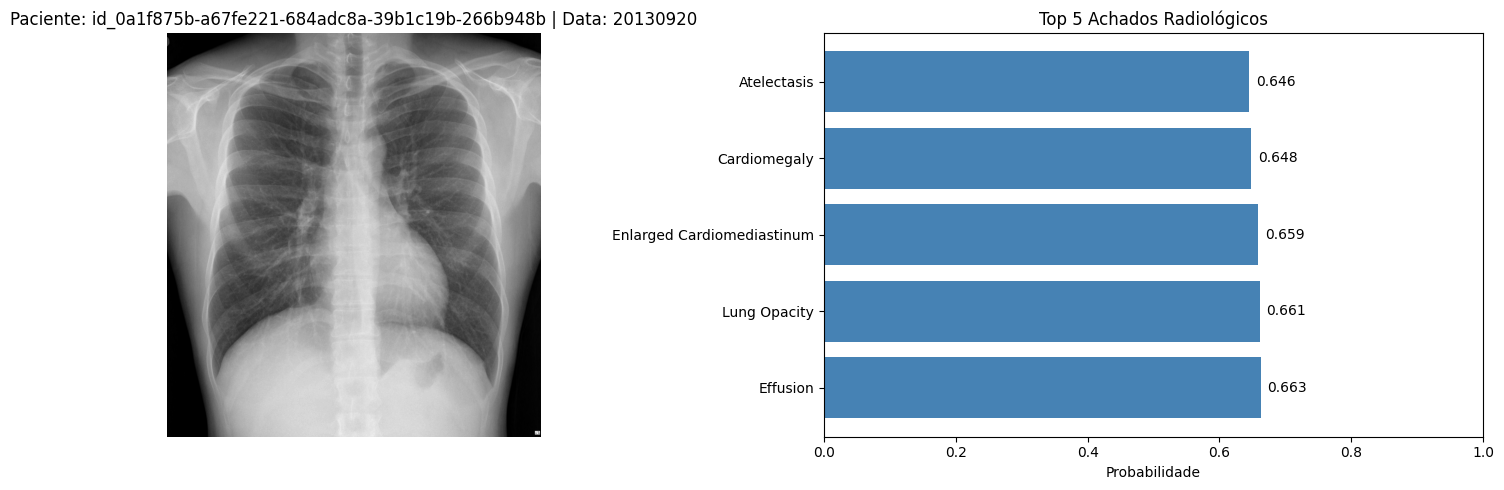


Metadados DICOM:
  patient_id: id_0a1f875b-a67fe221-684adc8a-39b1c19b-266b948b
  study_date: 20130920
  modality: CR
  image_shape: (2794, 2585)


Instância 2/9 - ID: 1f2d2901-0e995924-103fdbf4-8aacb8be-4279c8da
  → Baixando arquivo DICOM...
    Tamanho: 10477646 bytes
  → Chamando API de inferência...
    Inferência concluída


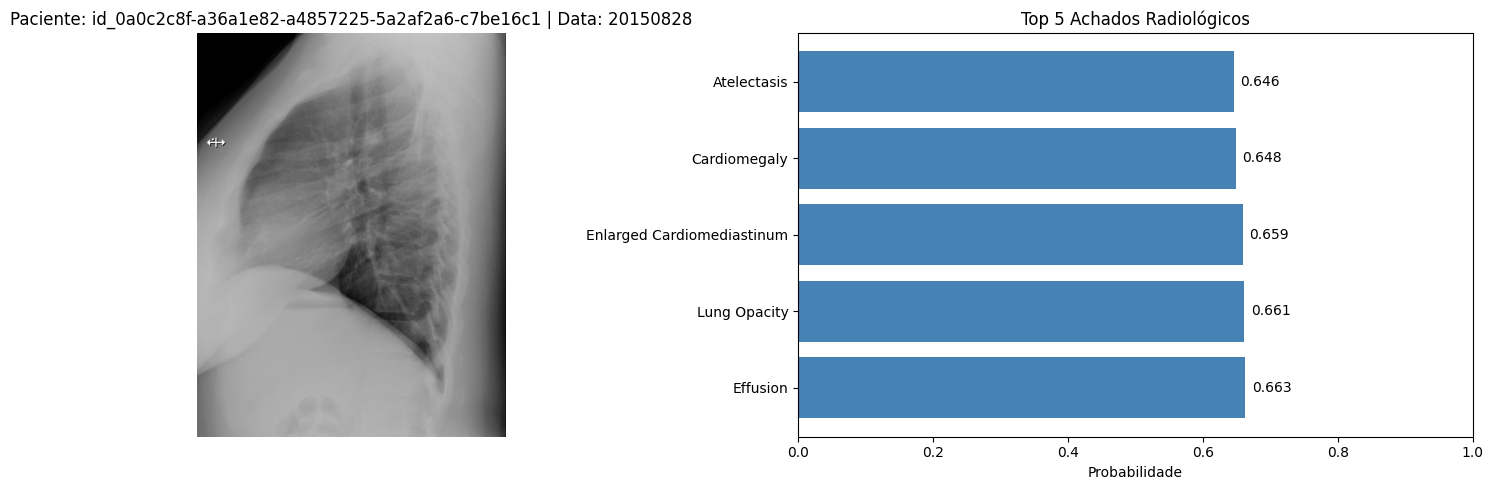


Metadados DICOM:
  patient_id: id_0a0c2c8f-a36a1e82-a4857225-5a2af2a6-c7be16c1
  study_date: 20150828
  modality: CR
  image_shape: (2619, 2000)


Instância 3/9 - ID: 25cc82b9-38583a9e-8a08fc15-f4892024-28b8584b
  → Baixando arquivo DICOM...
    Tamanho: 10365806 bytes
  → Chamando API de inferência...
    Inferência concluída


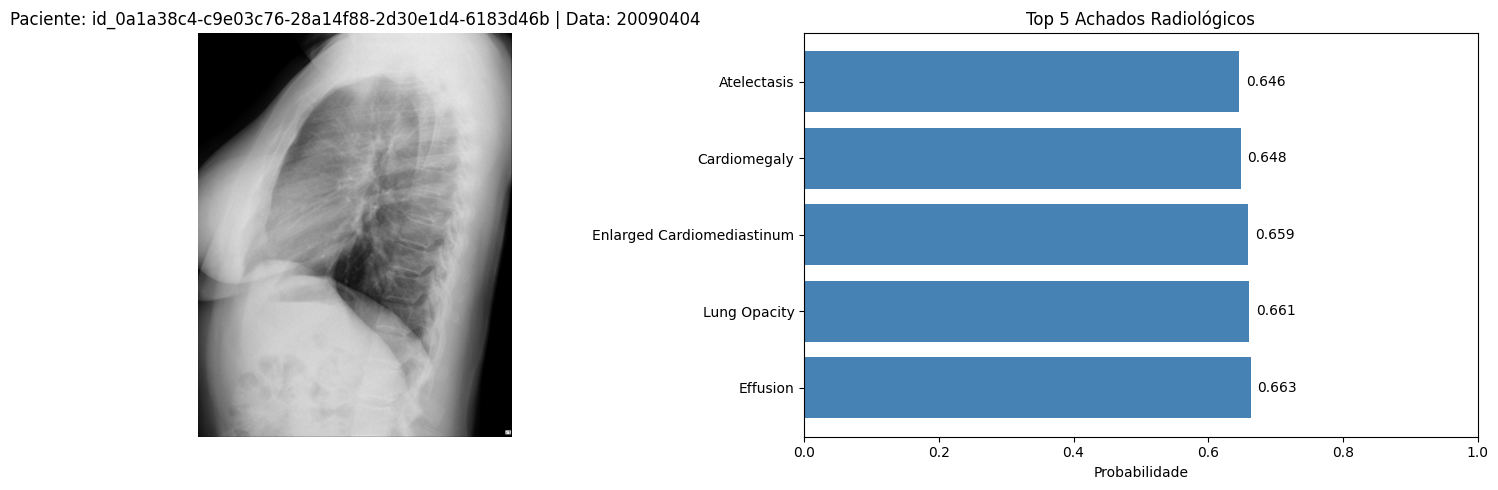


Metadados DICOM:
  patient_id: id_0a1a38c4-c9e03c76-28a14f88-2d30e1d4-6183d46b
  study_date: 20090404
  modality: CR
  image_shape: (2582, 2007)


Instância 4/9 - ID: 70d0117e-60d4002b-cbbe9042-3b57555a-e88bfd99
  → Baixando arquivo DICOM...
    Tamanho: 13334576 bytes
  → Chamando API de inferência...
    Inferência concluída


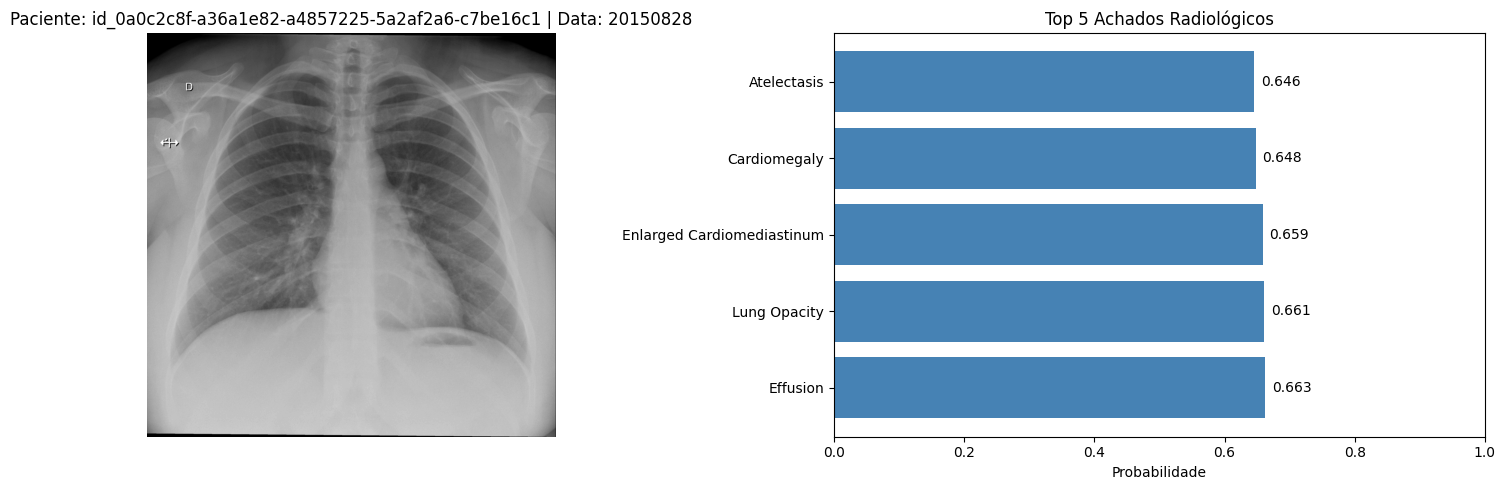


Metadados DICOM:
  patient_id: id_0a0c2c8f-a36a1e82-a4857225-5a2af2a6-c7be16c1
  study_date: 20150828
  modality: CR
  image_shape: (2566, 2598)


Instância 5/9 - ID: 76a9a673-cdfbc0e8-efa364cc-27c25423-aad7ec6c
  → Baixando arquivo DICOM...
    Tamanho: 14060458 bytes
  → Chamando API de inferência...
    Inferência concluída


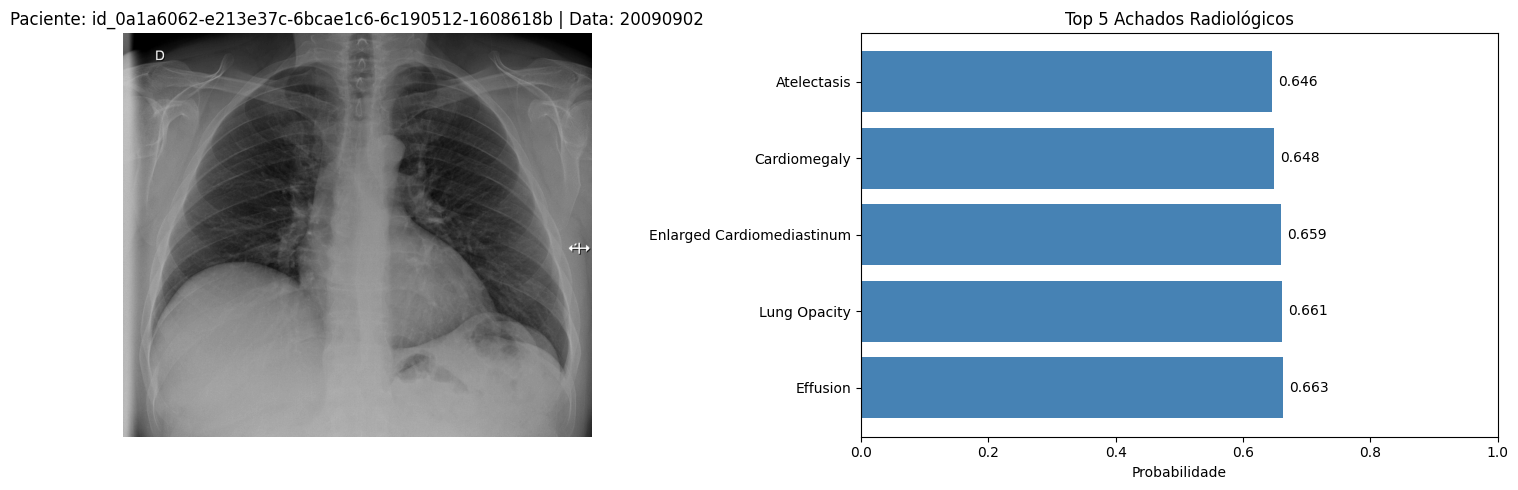


Metadados DICOM:
  patient_id: id_0a1a6062-e213e37c-6bcae1c6-6c190512-1608618b
  study_date: 20090902
  modality: CR
  image_shape: (2463, 2854)


Instância 6/9 - ID: 8206ee5f-8f834b42-042e6a40-705b72da-bc7ce3a3
  → Baixando arquivo DICOM...
    Tamanho: 5362102 bytes
  → Chamando API de inferência...
    Inferência concluída


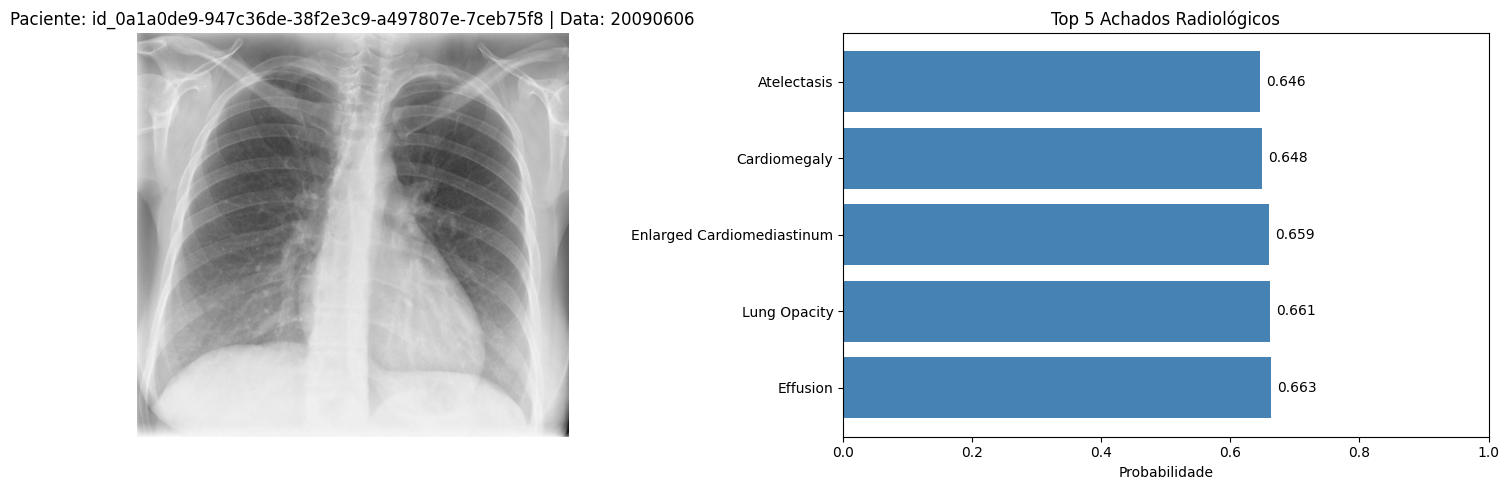


Metadados DICOM:
  patient_id: id_0a1a0de9-947c36de-38f2e3c9-a497807e-7ceb75f8
  study_date: 20090606
  modality: DX
  image_shape: (1584, 1692)


Instância 7/9 - ID: 89713983-98986f53-c67e566f-6786c944-1697687d
  → Baixando arquivo DICOM...
    Tamanho: 12584012 bytes
  → Chamando API de inferência...
    Inferência concluída


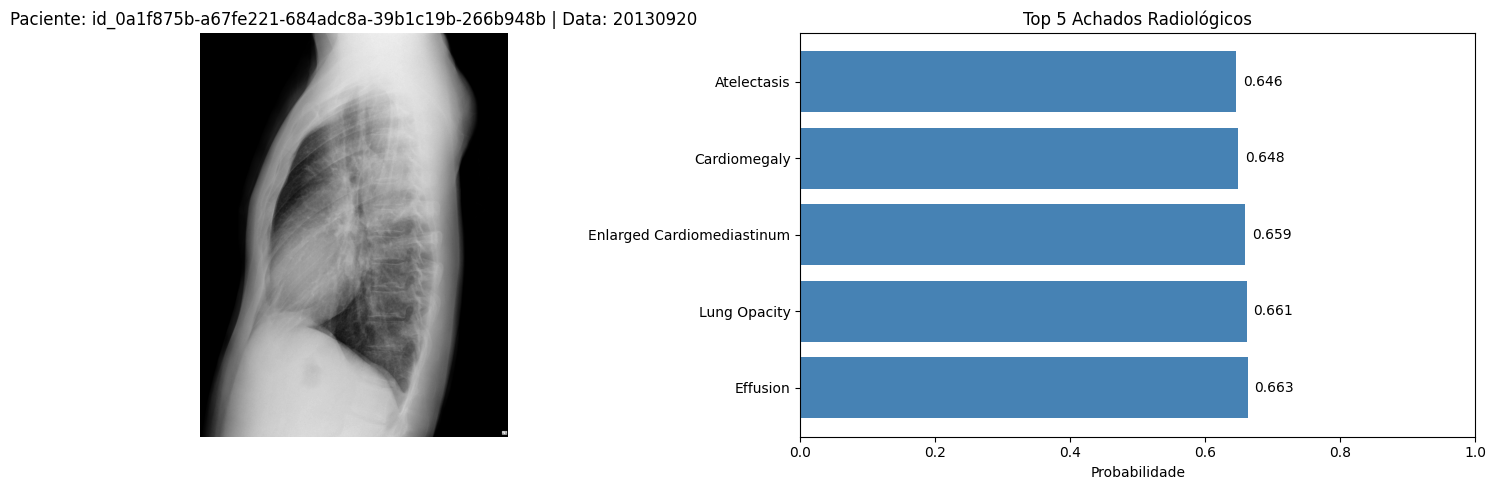


Metadados DICOM:
  patient_id: id_0a1f875b-a67fe221-684adc8a-39b1c19b-266b948b
  study_date: 20130920
  modality: CR
  image_shape: (2874, 2189)


Instância 8/9 - ID: b8eaee70-ed5ace3a-2f77895e-8105e3d3-ec3508ce
  → Baixando arquivo DICOM...
    Tamanho: 10289306 bytes
  → Chamando API de inferência...
    Inferência concluída


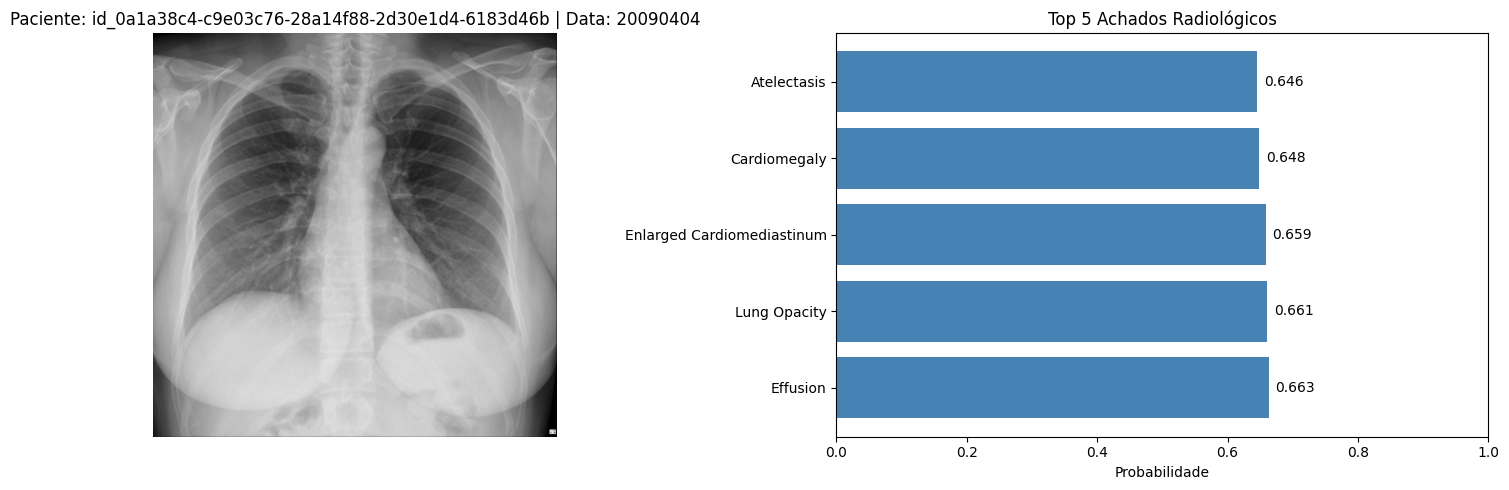


Metadados DICOM:
  patient_id: id_0a1a38c4-c9e03c76-28a14f88-2d30e1d4-6183d46b
  study_date: 20090404
  modality: CR
  image_shape: (2268, 2268)


Instância 9/9 - ID: f816ed6a-8177f2bc-53267934-dc56e141-86749fb2
  → Baixando arquivo DICOM...
    Tamanho: 11009270 bytes
  → Chamando API de inferência...
    Inferência concluída


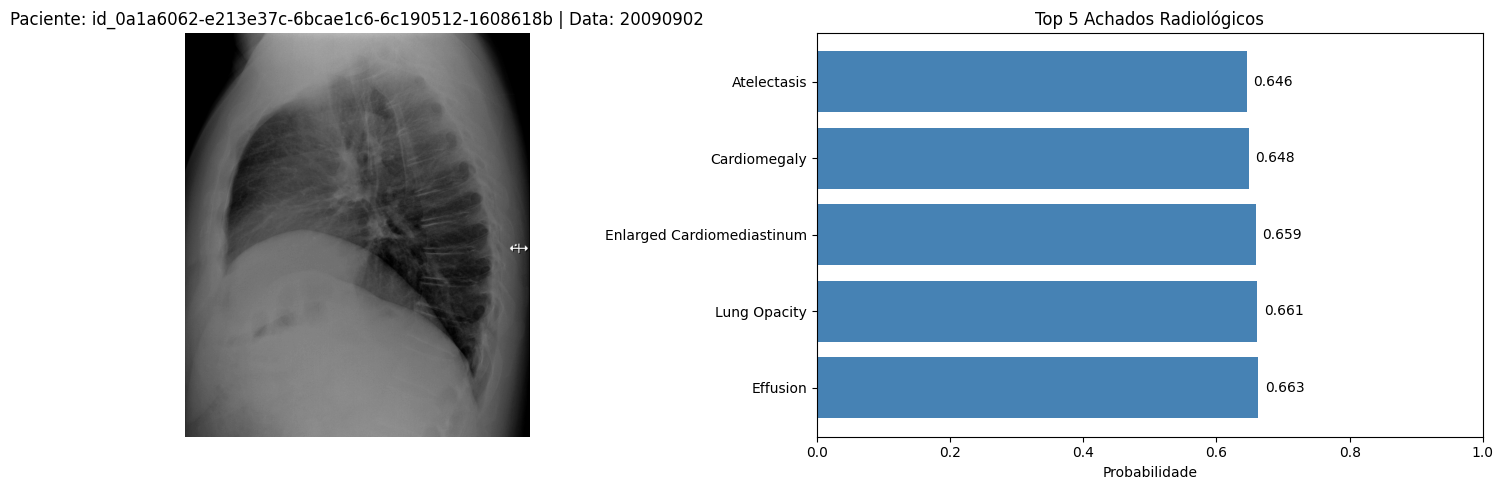


Metadados DICOM:
  patient_id: id_0a1a6062-e213e37c-6bcae1c6-6c190512-1608618b
  study_date: 20090902
  modality: CR
  image_shape: (2541, 2166)


✓ Processamento concluído!


In [5]:
if not instances:
    print("⚠️  Sem instâncias para processar. Execute as células anteriores.")
else:
    print(f"Processando {len(instances)} instância(s)...\n")

    for idx, instance_id in enumerate(instances, 1):
        print(f"{'='*80}")
        print(f"Instância {idx}/{len(instances)} - ID: {instance_id}")
        print(f"{'='*80}")

        try:
            # Obtém informações da instância
            info = get_instance_info(instance_id)
            patient_id = info.get("PatientID", "N/A")
            study_date = info.get("StudyDate", "N/A")

            title = f"Paciente: {patient_id} | Data: {study_date}"

            # Baixa o DICOM
            print("  → Baixando arquivo DICOM...")
            dicom_bytes = download_dicom(instance_id)
            print(f"    Tamanho: {len(dicom_bytes)} bytes")

            # Chama API de inferência
            print("  → Chamando API de inferência...")
            predictions = call_inference_api(dicom_bytes)
            print("    Inferência concluída")

            # Exibe resultados
            display_image_and_predictions(dicom_bytes, predictions, title)

            print("\n")

        except Exception as e:
            print(f"  ✗ Erro ao processar instância {instance_id}: {e}")
            print("\n")
            continue

    print(f"{'='*80}")
    print("✓ Processamento concluído!")
    print(f"{'='*80}")

## 6. Análise Consolidada (Opcional)

In [6]:
if instances:
    print("Gerando análise consolidada de todos os exames...\n")

    all_predictions = []

    for instance_id in instances:
        try:
            dicom_bytes = download_dicom(instance_id)
            predictions = call_inference_api(dicom_bytes)
            probs = predictions.get("probabilities", {})

            # Pega top 3 achados
            top_3 = dict(list(probs.items())[:3])
            all_predictions.append({
                "instance_id": instance_id[:8] + "...",
                **top_3
            })
        except Exception as e:
            print(f"Erro ao processar {instance_id}: {e}")

    if all_predictions:
        df = pd.DataFrame(all_predictions)
        print("Top 3 achados por instância:")
        print(df.to_string(index=False))
else:
    print("Sem instâncias para análise consolidada.")

Gerando análise consolidada de todos os exames...

Top 3 achados por instância:
instance_id  Effusion  Lung Opacity  Enlarged Cardiomediastinum
1a368e54...  0.662998      0.661264                    0.659113
1f2d2901...  0.662992      0.661256                    0.659078
25cc82b9...  0.662966      0.661241                    0.659082
70d0117e...  0.662935      0.661247                    0.659091
76a9a673...  0.662973      0.661260                    0.659087
8206ee5f...  0.663033      0.661291                    0.659111
89713983...  0.662904      0.661214                    0.659059
b8eaee70...  0.662995      0.661267                    0.659104
f816ed6a...  0.663010      0.661272                    0.659097
